# 03 Sensitivity

How much does the answer from notebook 02 depend on the uncertain inputs? Each point below is the optimal hybrid (solar, battery and a main generator all allowed), then run hour by hour with the no-foresight rule plus the clinic/school backup generator, exactly like the final design in notebook 02. Sweeps (`src/sensitivity.py`):

| Sweep | Values |
|---|---|
| Delivered diesel price | $0.50 to $3.00 per litre (today: about $2.68) |
| Li-ion battery cost | -30 %, median ($314/kWh), +30 % |
| ESMAP component costs | 25th and 75th percentile for PV, battery and inverter, each on its own (others at the median); and all three together as outer bounds (ESMAP's note says the percentiles should not be read together) |
| Reliability target | households may go without 0 %, 1 % or 5 % of their energy |
| Discount rate | 6.41 % (ESMAP's real rate), 10 % (base), 15 % |
| Demand growth | households +5 % a year in years 1-5, flat to year 20; size for today, or for year 5; shortfall in year 5 and delivered cost over 20 years |

All for the low clinic case; both household demand cases.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG, PROC = ROOT / "figures", ROOT / "data" / "processed"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 30)
import sensitivity as se, costs as cst, demand as dm, solar

In [2]:
# Results are cached; delete data/processed/sensitivity*.parquet to recompute (~7 minutes).
f1, f2 = PROC / "sensitivity.parquet", PROC / "sensitivity_diesel_only.parquet"
if not (f1.exists() and f2.exists()):
    if not (PROC / "demand.parquet").exists():
        PROC.mkdir(parents=True, exist_ok=True); dm.build_all().to_parquet(PROC / "demand.parquet")
    if not (PROC / "pv_per_kwp.parquet").exists():
        solar.pv_per_kwp().to_frame().to_parquet(PROC / "pv_per_kwp.parquet")
    d = pd.read_parquet(PROC / "demand.parquet"); pv = pd.read_parquet(PROC / "pv_per_kwp.parquet")["pv_per_kwp"]
    res, dsl = se.run_all(d, pv); res["value"] = res["value"].astype(str)
    res.to_parquet(f1); dsl.to_parquet(f2)
res, dsl = pd.read_parquet(f1), pd.read_parquet(f2)
cols = ["PV kWp", "battery kWh", "main diesel kW", "backup generator kW", "households unserved %",
        "hours with household shortfall", "longest household outage h", "clinic/school hours cut", "diesel litres/yr", "LCOE delivered $/kWh", "LCOE delivered N/kWh"]

## 1. Diesel price: when does a generator come back?

In [3]:
ds = res[res.sweep == "diesel $/L"].assign(price=lambda x: x.value.astype(float))
ds.set_index(["demand", "price"])[cols]

PV kWp  battery kWh  main diesel kW  backup generator kW  \
demand price                                                             
low    0.50     8.14         0.00           11.60                  3.0   
       0.75    24.69        69.44            4.88                  3.0   
       1.00    41.30       131.78            0.91                  3.0   
       1.25    43.64       133.20            0.66                  3.0   
       1.50    46.69       133.65            0.36                  3.0   
       2.00    49.56       134.63            0.12                  3.0   
       2.68    51.22       135.15            0.00                  3.0   
       3.00    51.22       135.15            0.00                  3.0   
high   0.50    34.22         8.30           45.20                  3.0   
       0.75    95.31       273.65           21.11                  3.0   
       1.00   169.27       557.12            2.98                  3.0   
       1.25   177.73       559.04            2.15                  3.0   
       1.50   188.70       560.68            1.06                  3.0   
       2.00   200.54       563.81            0.00                  3.0   
       2.68   200.54       563.81            0.00                  3.0   
       3.00   200.54       563.81            0.00                  3.0   

              households unserved %  hours with household shortfall  \
demand price                                                          
low    0.50                    5.00                            1434   
       0.75                    9.73                            1733   
       1.00                    8.36                             914   
       1.25                    7.29                             754   
       1.50                    6.17                             629   
       2.00                    5.11                             522   
       2.68                    4.62                             474   
       3.00                    4.62                             474   
high   0.50                    5.92                            1743   
       0.75                    9.84                            1731   
       1.00                    7.44                             846   
       1.25                    6.77                             738   
       1.50                    5.92                             629   
       2.00                    4.91                             524   
       2.68                    4.91                             524   
       3.00                    4.91                             524   

              longest household outage h  clinic/school hours cut  \
demand price                                                        
low    0.50                            4                        0   
       0.75                            6                        0   
       1.00                           13                        0   
       1.25                           13                        0   
       1.50                           13                        0   
       2.00                           13                        0   
       2.68                           13                        0   
       3.00                           13                        0   
high   0.50                            5                        0   
       0.75                            6                        0   
       1.00                           13                        0   
       1.25                           13                        0   
       1.50                           13                        0   
       2.00                           13                        0   
       2.68                           13                        0   
       3.00                           13                        0   

              diesel litres/yr  LCOE delivered $/kWh  LCOE delivered N/kWh  
demand price                                                                
low  

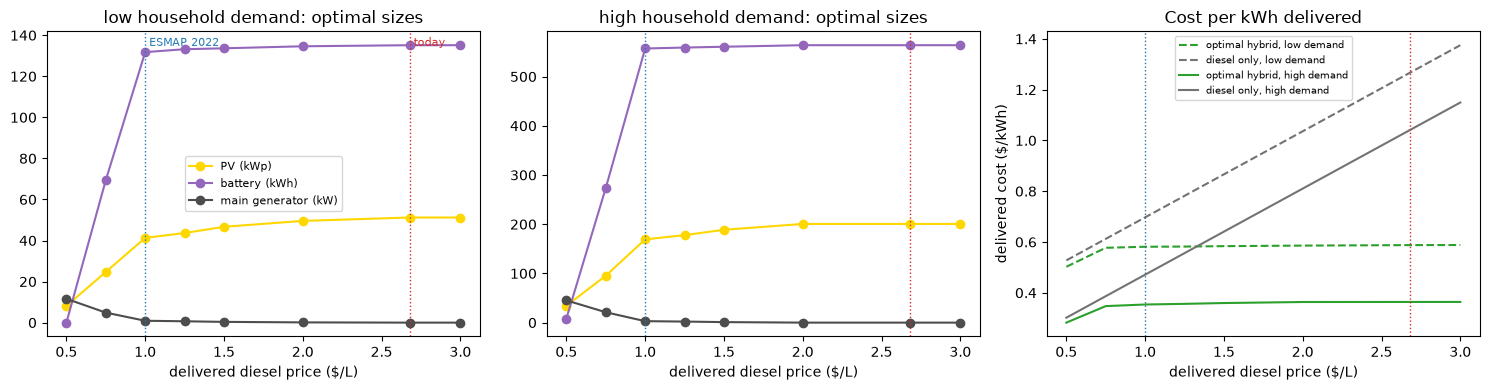

In [4]:
today, esmap = cst.diesel_usd_per_litre(), 1.00
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, dem in zip(axs[:2], ("low", "high")):
    x = ds[ds.demand == dem].sort_values("price")
    ax.plot(x.price, x["PV kWp"], "o-", color="gold", label="PV (kWp)")
    ax.plot(x.price, x["battery kWh"], "o-", color="tab:purple", label="battery (kWh)")
    ax.plot(x.price, x["main diesel kW"], "o-", color="0.3", label="main generator (kW)")
    ax.set_title(f"{dem} household demand: optimal sizes"); ax.set_xlabel("delivered diesel price ($/L)")
for dem, style in (("low", "--"), ("high", "-")):
    x = ds[ds.demand == dem].sort_values("price"); y = dsl[dsl.demand == dem].sort_values("value")
    axs[2].plot(x.price, x["LCOE delivered $/kWh"], style, color="tab:green", label=f"optimal hybrid, {dem} demand")
    axs[2].plot(y.value, y["LCOE delivered $/kWh"], style, color="0.45", label=f"diesel only, {dem} demand")
axs[2].set_xlabel("delivered diesel price ($/L)"); axs[2].set_ylabel("delivered cost ($/kWh)"); axs[2].set_title("Cost per kWh delivered")
for ax in axs:
    ax.axvline(today, color="tab:red", ls=":", lw=1); ax.axvline(esmap, color="tab:blue", ls=":", lw=1)
axs[0].legend(fontsize=8); axs[2].legend(fontsize=7)
axs[0].text(today, axs[0].get_ylim()[1] * 0.95, " today", color="tab:red", fontsize=8)
axs[0].text(esmap, axs[0].get_ylim()[1] * 0.95, " ESMAP 2022", color="tab:blue", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "diesel_price_sweep.png", dpi=150)

In [5]:
def entry_price(dem):
    x = ds[(ds.demand == dem) & (ds["main diesel kW"] > 0.5)].sort_values("price")
    return x.price.max() if len(x) else None
pd.Series({dem: entry_price(dem) for dem in ("low", "high")}, name="highest diesel price ($/L) at which the optimum still builds a main generator").to_frame()

,highest diesel price ($/L) at which the optimum still builds a main generator
low,1.25
high,1.50


## 2. Equipment costs

In [6]:
cost_sweeps = res[res.sweep.isin(["battery $/kWh"]) | res.sweep.str.startswith("ESMAP cost") | (res.sweep == "all components (bounds)")]
cost_sweeps.set_index(["sweep", "demand", "value"])[cols]

PV kWp  battery kWh  \
sweep                     demand value                                  
battery $/kWh             low    220               50.37       137.57   
                                 314               51.22       135.15   
                                 408               51.80       133.96   
ESMAP cost: PV only       low    25th percentile   51.43       134.93   
                                 75th percentile   50.52       135.85   
ESMAP cost: battery only  low    25th percentile   50.95       135.88   
                                 75th percentile   51.83       133.92   
ESMAP cost: inverter only low    25th percentile   50.90       135.09   
                                 75th percentile   52.03       135.38   
all components (bounds)   low    25th percentile   50.69       135.47   
                                 median            51.22       135.15   
                                 75th percentile   51.46       134.45   
battery $/kWh             high   220              198.93       568.37   
                                 314              200.54       563.81   
                                 408              202.71       560.26   
ESMAP cost: PV only       high   25th percentile  201.27       563.29   
                                 75th percentile  199.24       565.46   
ESMAP cost: battery only  high   25th percentile  200.12       564.95   
                                 75th percentile  202.77       560.17   
ESMAP cost: inverter only high   25th percentile  199.60       563.88   
                                 75th percentile  204.96       564.16   
all components (bounds)   high   25th percentile  199.93       564.33   
                                 median           200.54       563.81   
                                 75th percentile  204.03       563.10   

                                                  main diesel kW  \
sweep                     demand value                             
battery $/kWh             low    220                        0.00   
                                 314                        0.00   
                                 408                        0.00   
ESMAP cost: PV only       low    25th percentile            0.00   
                                 75th percentile            0.00   
ESMAP cost: battery only  low    25th percentile            0.00   
                                 75th percentile            0.00   
ESMAP cost: inverter only low    25th percentile            0.00   
                                 75th percentile            0.00   
all components (bounds)   low    25th percentile            0.00   
                                 median                     0.00   
                                 75th percentile            0.04   
battery $/kWh             high   220                        0.00   
                                 314                        0.00   
                                 408                        0.00   
ESMAP cost: PV only       high   25th percentile            0.00   
                                 75th percentile            0.00   
ESMAP cost: battery only  high   25th percentile            0.00   
                                 75th percentile            0.00   
ESMAP cost: inverter only high   25th percentile            0.00   
                                 75th percentile            0.00   
all components (bounds)   high   25th percentile            0.00   
                                 median                     0.00   
                                 75th percentile            0.00   

                                                  backup generator kW  \
sweep                     demand value                                  
battery $/kWh             low    220                              3.0   
                                 314                              3.0   
                                 408                              3.0   
ESMAP cost: PV on

## 3. Reliability target

In [7]:
rel = res[res.sweep == "households unserved target %"]
rel.set_index(["demand", "value"])[cols]

PV kWp  battery kWh  main diesel kW  backup generator kW  \
demand value                                                             
low    0.0     52.19       135.45            2.54                  3.0   
       1.0     52.30       135.44            1.52                  3.0   
       5.0     51.22       135.15            0.00                  3.0   
high   0.0    211.81       566.68           10.66                  3.0   
       1.0    211.81       566.68            5.94                  3.0   
       5.0    200.54       563.81            0.00                  3.0   

              households unserved %  hours with household shortfall  \
demand value                                                          
low    0.0                     2.39                             286   
       1.0                     3.19                             364   
       5.0                     4.62                             474   
high   0.0                     2.18                             240   
       1.0                     2.95                             359   
       5.0                     4.91                             524   

              longest household outage h  clinic/school hours cut  \
demand value                                                        
low    0.0                            10                        0   
       1.0                            13                        0   
       5.0                            13                        0   
high   0.0                             7                        0   
       1.0                            12                        0   
       5.0                            13                        0   

              diesel litres/yr  LCOE delivered $/kWh  LCOE delivered N/kWh  
demand value                                                                
low    0.0              319.90                  0.60                829.42  
       1.0              203.71                  0.59                825.32  
       5.0               53.25                  0.59                817.99  
high   0.0             1279.53                  0.38                529.24  
       1.0              773.74                  0.38                522.39  
       5.0               54.83                  0.36                506.38

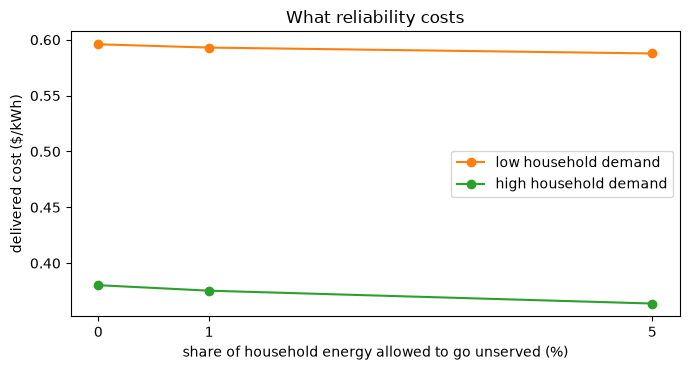

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for dem, c in (("low", "tab:orange"), ("high", "tab:green")):
    x = rel[rel.demand == dem].assign(t=lambda y: y.value.astype(float)).sort_values("t")
    ax.plot(x.t, x["LCOE delivered $/kWh"], "o-", color=c, label=f"{dem} household demand")
ax.set_xlabel("share of household energy allowed to go unserved (%)"); ax.set_ylabel("delivered cost ($/kWh)")
ax.set_xticks([0, 1, 5]); ax.legend(); ax.set_title("What reliability costs")
fig.tight_layout(); fig.savefig(FIG / "reliability_cost.png", dpi=150)

Note: the 0 % and 1 % designs are sized by the optimiser with perfect foresight; run with the no-foresight rule they still leave some household energy unserved (column *households unserved %*).

## 4. Discount rate

In [9]:
res[res.sweep == "discount rate %"].set_index(["demand", "value"])[cols]

PV kWp  battery kWh  main diesel kW  backup generator kW  \
demand value                                                             
low    6.41    51.64       134.69            0.00                  3.0   
       10.0    51.22       135.15            0.00                  3.0   
       15.0    49.20       135.05            0.12                  3.0   
high   6.41   202.07       562.59            0.00                  3.0   
       10.0   200.54       563.81            0.00                  3.0   
       15.0   199.88       564.49            0.00                  3.0   

              households unserved %  hours with household shortfall  \
demand value                                                          
low    6.41                    4.62                             481   
       10.0                    4.62                             474   
       15.0                    5.09                             518   
high   6.41                    4.91                             534   
       10.0                    4.91                             524   
       15.0                    4.91                             513   

              longest household outage h  clinic/school hours cut  \
demand value                                                        
low    6.41                           13                        0   
       10.0                           13                        0   
       15.0                           13                        0   
high   6.41                           13                        0   
       10.0                           13                        0   
       15.0                           13                        0   

              diesel litres/yr  LCOE delivered $/kWh  LCOE delivered N/kWh  
demand value                                                                
low    6.41              52.87                  0.49                687.90  
       10.0              53.25                  0.59                817.99  
       15.0              67.25                  0.73               1015.44  
high   6.41              54.25                  0.30                422.85  
       10.0              54.83                  0.36                506.38  
       15.0              55.45                  0.46                634.02

## 5. Demand growth: size for today or for year 5?

Households grow 5 % a year in years 1-5 and stay flat to year 20 (the clinic and school do not grow; the 312 customers in the distribution cost are held fixed). *LCOE delivered* in the table is the year-5 snapshot; *lifetime LCOE* is the sum of discounted yearly costs over 20 years divided by the sum of discounted energy served.

In [10]:
res[res.sweep == "demand growth"].set_index(["demand", "value"])[cols + ["lifetime LCOE delivered $/kWh"]]

PV kWp  battery kWh  main diesel kW  \
demand value                                                   
low    sized for today    51.22       135.15             0.0   
       sized for year 5   62.67       169.50             0.0   
high   sized for today   200.54       563.81             0.0   
       sized for year 5  253.53       716.90             0.0   

                         backup generator kW  households unserved %  \
demand value                                                          
low    sized for today                   3.0                  20.38   
       sized for year 5                  3.0                   4.70   
high   sized for today                   3.0                  21.38   
       sized for year 5                  3.0                   4.93   

                         hours with household shortfall  \
demand value                                              
low    sized for today                             2470   
       sized for year 5                             493   
high   sized for today                             2809   
       sized for year 5                             530   

                         longest household outage h  clinic/school hours cut  \
demand value                                                                   
low    sized for today                           13                        0   
       sized for year 5                          13                        0   
high   sized for today                           13                        0   
       sized for year 5                          13                        0   

                         diesel litres/yr  LCOE delivered $/kWh  \
demand value                                                      
low    sized for today             242.29                  0.57   
       sized for year 5             53.74                  0.53   
high   sized for today             258.70                  0.35   
       sized for year 5             54.89                  0.35   

                         LCOE delivered N/kWh  lifetime LCOE delivered $/kWh  
demand value                                                                  
low    sized for today                 791.52                           0.57  
       sized for year 5                743.17                           0.55  
high   sized for today                 484.69                           0.35  
       sized for year 5                485.52                           0.36

## 6. Everything at once (high household demand)

,input,low,high,low label,high label
0,diesel price,0.35,0.36,$0.75/L,$3.00/L
1,battery cost,0.32,0.41,-30 %,+30 %
2,PV cost only,0.36,0.38,25th pct,75th pct
3,battery cost only (ESMAP),0.34,0.41,25th pct,75th pct
4,inverter cost only,0.36,0.38,25th pct,75th pct
5,all components (bounds),0.33,0.45,all 25th,all 75th
6,discount rate,0.30,0.46,6.41 %,15 %
7,reliability target,0.36,0.38,5 % unserved,0 % unserved


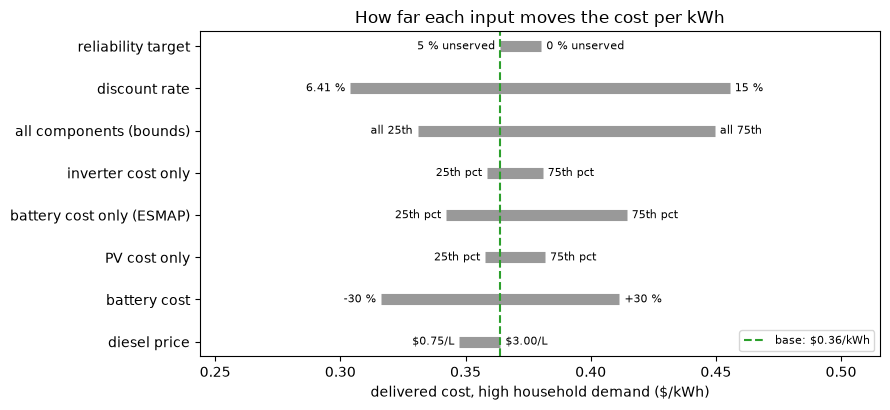

In [11]:
base = ds[(ds.demand == "high") & np.isclose(ds.price, round(today, 2))]["LCOE delivered $/kWh"].iloc[0]
rows = []
spec = [("diesel price", "diesel $/L", "0.75", "3.0", "$0.75/L", "$3.00/L"),
        ("battery cost", "battery $/kWh", None, None, "-30 %", "+30 %"),
        ("PV cost only", "ESMAP cost: PV only", "25th percentile", "75th percentile", "25th pct", "75th pct"),
        ("battery cost only (ESMAP)", "ESMAP cost: battery only", "25th percentile", "75th percentile", "25th pct", "75th pct"),
        ("inverter cost only", "ESMAP cost: inverter only", "25th percentile", "75th percentile", "25th pct", "75th pct"),
        ("all components (bounds)", "all components (bounds)", "25th percentile", "75th percentile", "all 25th", "all 75th"),
        ("discount rate", "discount rate %", "6.41", "15.0", "6.41 %", "15 %"),
        ("reliability target", "households unserved target %", "5.0", "0.0", "5 % unserved", "0 % unserved")]
for label, sweep, lo, hi, lo_txt, hi_txt in spec:
    x = res[(res.sweep == sweep) & (res.demand == "high")].set_index("value")["LCOE delivered $/kWh"]
    if lo is None:
        lo, hi = x.index[0], x.index[-1]
    rows.append({"input": label, "low": x[lo], "high": x[hi], "low label": lo_txt, "high label": hi_txt})
t = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, r in t.iterrows():
    a, b = sorted([r.low, r.high])
    ax.plot([a, b], [i, i], color="0.6", lw=8, solid_capstyle="butt")
    if b - a < 0.004:
        ax.text(b + 0.003, i, f"no change from {r['low label']} to {r['high label']}", va="center", fontsize=8)
    else:
        ax.text(a - 0.002, i, r["low label"] if r.low <= r.high else r["high label"], va="center", ha="right", fontsize=8)
        ax.text(b + 0.002, i, r["high label"] if r.low <= r.high else r["low label"], va="center", ha="left", fontsize=8)
ax.axvline(base, color="tab:green", ls="--", label=f"base: ${base:.2f}/kWh")
ax.set_yticks(range(len(t)), t.input); ax.set_xlim(min(t.low.min(), t.high.min()) - 0.06, max(t.low.max(), t.high.max()) + 0.06)
ax.set_xlabel("delivered cost, high household demand ($/kWh)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("How far each input moves the cost per kWh")
fig.tight_layout(); fig.savefig(FIG / "sensitivity_range.png", dpi=150)
t

## What this shows

- **The design is insulated from the diesel price; diesel-only is not.** At $2.00 a litre or more the optimum builds no main generator, and the cost per kWh stays at $0.364 (high demand) and $0.588 (low) whatever diesel costs. The largest price at which a main generator (over 0.5 kW) is still built is $1.50 (high, 1.1 kW) and $1.25 (low, 0.7 kW). Diesel only climbs from $0.30 (high) / $0.53 (low) at $0.50 a litre to $1.15 / $1.38 at $3.00.
- **A main generator only makes sense with cheap diesel.** At $0.50 a litre the optimum is diesel-led (45 kW of generator and 34 kWp of PV for high demand; 12 kW and 8 kWp for low). At $0.75 it is mostly solar with a 21 kW (high) or 5 kW (low) generator, and at ESMAP's 2022 assumption of $1 a litre the generator is 3 kW (high) or under 1 kW (low). Below about $1.50 the no-foresight rule leaves households short 6-10 % of their energy, above the 5 % target. RLI's design for this cluster (77 kW generator) was made on assumptions that are not in the dataset, so no diesel price can be inferred from it.
- **Equipment costs move the price by 5-25 %, with the battery the most influential component.** Each of PV, battery and inverter at ESMAP's 25th and 75th percentile on its own (high demand): PV $0.358-0.382, battery $0.342-0.414, inverter $0.358-0.381 per kWh against $0.364 at the median. Low demand: PV $0.582-0.606, battery $0.567-0.637, inverter $0.583-0.604 against $0.588. All three together ($0.331-0.450 high, $0.555-0.671 low) are outer bounds only; ESMAP's note says the percentiles are not meant to be read together. A battery price of -30 % / +30 % gives $0.316-0.411 (high) and $0.541-0.634 (low). The sizes barely change.
- **The discount rate matters as much as any equipment price.** At ESMAP's real rate of 6.41 % the cost is $0.304 (high) and $0.494 (low); at 15 % it is $0.456 and $0.730, against $0.364 and $0.588 at the 10 % base. The household demand case (about $0.36 against $0.59) and the fixed costs (distribution and staff, $14,262 a year in every case) are as large as any of these.
- **Full reliability costs little, but foresight is not free.** Asking the optimiser for 0 % instead of 5 % household shortfall raises the cost per kWh by 1.6 US cents (high: $0.380 against $0.364) and 0.8 cents (low: $0.596 against $0.588), adding PV and a 2.5-11 kW main generator. Run without foresight (with the backup generator), those designs still leave households short 2.2-2.4 % (0 % target) and 3.0-3.2 % (1 % target) of their energy.
- **Growth.** Households growing 5 % a year for 5 years, then flat, on a system sized for today leave households short 20-21 % of their energy (2,470-2,810 hours) in year 5 and after. Sizing for year 5 (254 kWp and 717 kWh for high demand; 63 kWp and 170 kWh for low) restores 4.7-4.9 %. Over 20 years, discounted, the delivered cost is $0.351 (sized for today) against $0.359 (sized for year 5) for high demand and $0.571 against $0.549 for low. The system sized for today is not cheaper for the same service: it delivers about a fifth less to households in years 5 to 20. The 312 customers in the distribution cost are held fixed in all of this, and only households grow.

**Limits.** One typical weather year. Sweeps move one input at a time, except the "all components" bounds. Results are for the low clinic case; notebook 02 shows the clinic case changes little. The linear generator, half-load fuel rate and 2021 battery prices all favour diesel, so the generator thresholds above are conservative.
